# Notebook 1: Text Summarization and Its Evaluation Metrics

**What you will do:** build several summarizers (extractive from scratch, and a real abstractive model on Colab), then evaluate them with the metrics from the presentation: **ROUGE**, **BERTScore**, **factual consistency** (NLI-style and entity support), and a **metric sanity test** that shows what each metric can and cannot see.

**How the notebook is organised**

| Part | Content | Needs internet / GPU? |
|---|---|---|
| 1 | Data: 6 short news articles with human reference summaries | no |
| 2 | ROUGE from scratch (checked against `rouge-score`) | no |
| 3 | Extractive summarizers: Lead-k, TextRank, random, copy-everything | no |
| 4 | Abstractive summarizer (DistilBART) with automatic fallback | optional (Colab) |
| 5 | BERTScore: greedy matching from scratch + the real `bert-score` | real model optional |
| 6 | Factual consistency: entity/number support and NLI (SummaC-style) | NLI model optional |
| 7 | Metric sanity test: perturb a good summary and watch each metric | no |
| 8 | Meta-evaluation: do metrics agree with a quality ordering? | no |

**Safe by design:** every cell that needs a model is wrapped in `try/except`. If the model cannot be loaded (no internet, no GPU), the notebook prints a message and continues with a fallback, so **Run all** always works. Set `USE_MODELS = False` to skip models on purpose.

*All articles and names are fictional, written for this notebook.*

In [1]:
# Colab only: install the extra libraries (transformers and torch are already on Colab).
!pip -q install rouge-score bert-score sacrebleu

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re, math, random, zlib, collections
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.stats import spearmanr, kendalltau

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
random.seed(0); np.random.seed(0)

USE_MODELS = True   # set False to skip all neural models (the notebook still runs end to end)
print("Setup OK")

Setup OK


## Part 1: Data

Six short fictional news articles. Each has a **human reference summary** (1 to 2 sentences). In a real study you would use a large benchmark such as CNN/DailyMail or XSum (an optional cell below loads a small slice on Colab).

In [3]:
ARTICLES = [
 dict(id="bike", title="City bike lanes",
  text="The city council of Marlow voted 7 to 2 on Tuesday to build 40 kilometres of protected bike lanes by 2028. Mayor Elena Ortiz said the plan will cost 18 million euros and is partly funded by a national transport grant. Cycling already accounts for 9 percent of trips in Marlow, up from 4 percent in 2018. Local shop owners worried that removing parking spaces on Harbour Street would hurt sales. The council agreed to add 120 new spaces in a car park two blocks away. Construction on the first 12 kilometres will start in March. Residents can comment on the final route until the end of January.",
  reference="Marlow's council approved 40 km of protected bike lanes by 2028, costing 18 million euros. Parking lost on Harbour Street will be replaced with 120 spaces nearby."),
 dict(id="planet", title="Rocky planet discovered",
  text="Astronomers at the Aurora Observatory announced the discovery of a rocky planet orbiting a nearby red dwarf star 22 light years from Earth. The planet, named Kepa-4b, is about 1.3 times the size of Earth and circles its star every 11 days. Dr Samir Haddad, who led the team, said the planet sits at the edge of the habitable zone. Measurements of its atmosphere will begin next year using a space telescope. The team used data collected over six years. The findings were published in a peer reviewed journal on Monday. Other scientists called the result promising but cautioned that the star produces strong flares.",
  reference="Astronomers found a rocky planet, Kepa-4b, 22 light years away at the edge of its star's habitable zone. Atmosphere measurements begin next year, though strong stellar flares are a concern."),
 dict(id="steps", title="Walking and health",
  text="A study of 12,000 adults in Norland found that people who walked at least 7,000 steps a day had a 30 percent lower risk of early death. The research, led by Prof Anika Berg, followed participants for ten years. Gains levelled off beyond 10,000 steps. The study also found that brisk walking was linked to better results than slow walking. Critics noted that healthier people may simply walk more. The authors adjusted for age, income and smoking but said some bias may remain. Health officials said the results support existing advice to stay active.",
  reference="A ten-year study of 12,000 adults found that walking 7,000 steps a day was linked to a 30 percent lower risk of early death, with little extra benefit beyond 10,000. Critics say healthier people may walk more."),
 dict(id="energy", title="Quarterly earnings",
  text="Nordwind Energy reported a profit of 310 million dollars for the third quarter, up 14 percent from a year earlier. Revenue rose to 2.4 billion dollars, driven by strong demand for wind turbines in Europe. Chief executive Carla Mendes said orders for offshore projects doubled. The company also announced a plan to hire 800 engineers by the end of next year. Shares rose 5 percent in early trading. Analysts expect supply chain delays to weigh on the fourth quarter. The firm kept its annual forecast unchanged.",
  reference="Nordwind Energy's third-quarter profit rose 14 percent to 310 million dollars on strong turbine demand. It plans to hire 800 engineers, though analysts expect supply delays."),
 dict(id="school", title="Four day school week",
  text="Schools in the Valmont region will switch to a four day week from September to cope with a shortage of teachers. The change affects 54 schools and about 21,000 students. Classes will run longer on the other four days, finishing at half past four in the afternoon. Education director Tomas Reyes said the aim is to keep experienced teachers who might otherwise leave. Parents groups raised concerns about child care on Fridays. The region will open free supervised clubs in 30 schools to help families. A review of student results will take place after two years.",
  reference="Valmont's 54 schools will move to a four-day week in September to retain teachers. Free Friday clubs will open in 30 schools, and results will be reviewed after two years."),
 dict(id="leopard", title="Snow leopard survey",
  text="Conservationists counted 1,850 snow leopards across the Tessaly mountains, a rise of 12 percent since the last survey in 2019. The count relied on 400 camera traps placed at high altitude. Project leader Dr Mina Rao said community patrols and compensation for lost livestock helped reduce poaching. Climate change remains a threat because the snow line is moving higher. The government pledged 5 million dollars for new protected areas. The next survey is planned for 2029.",
  reference="A survey counted 1,850 snow leopards in the Tessaly mountains, up 12 percent since 2019, helped by patrols and livestock compensation. Climate change remains a threat."),
]
for a in ARTICLES:
    print(f"{a['id']:8s} article: {len(a['text'].split()):3d} words | reference: {len(a['reference'].split()):2d} words")
print("\nExample reference:", ARTICLES[0]["reference"])

bike     article: 108 words | reference: 27 words
planet   article: 105 words | reference: 30 words
steps    article:  94 words | reference: 37 words
energy   article:  86 words | reference: 26 words
school   article:  96 words | reference: 30 words
leopard  article:  76 words | reference: 26 words

Example reference: Marlow's council approved 40 km of protected bike lanes by 2028, costing 18 million euros. Parking lost on Harbour Street will be replaced with 120 spaces nearby.


In [4]:
# OPTIONAL (Colab, internet): load a small slice of the real CNN/DailyMail benchmark.
# The rest of the notebook uses the bundled articles above, so this cell is only for exploration.
try:
    from datasets import load_dataset
    cnn = load_dataset("abisee/cnn_dailymail", "3.0.0", split="test[:5]")
    print("Loaded", len(cnn), "CNN/DailyMail test articles. Keys:", list(cnn[0].keys()))
    print("Reference highlights:", cnn[0]["highlights"][:200])
except Exception as e:
    print("Skipped (dataset not available here):", type(e).__name__)

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  259MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

Loaded 5 CNN/DailyMail test articles. Keys: ['article', 'highlights', 'id']
Reference highlights: Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war crimes 


## Part 2: ROUGE from scratch

**ROUGE** = **R**ecall-**O**riented **U**nderstudy for **G**isting **E**valuation. It counts overlap between a candidate summary and a reference.

* **ROUGE-N:** overlap of n-grams. We report precision, recall and F1.
  * precision = matched n-grams / n-grams in the **candidate**
  * recall = matched n-grams / n-grams in the **reference**
* **ROUGE-L:** based on the **longest common subsequence** (LCS), so word order matters.

Matching uses *clipped* counts: a word cannot be matched more times than it appears in the reference.

In [5]:
def tok(s):
    # same tokenisation as the rouge-score library: lowercase, keep a-z and 0-9
    return re.findall(r"[a-z0-9]+", s.lower())

def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def prf(overlap, n_cand, n_ref):
    p = overlap / n_cand if n_cand else 0.0
    r = overlap / n_ref if n_ref else 0.0
    f = 2 * p * r / (p + r) if (p + r) else 0.0
    return p, r, f

def rouge_n(ref, cand, n=1):
    r, c = ngram_counts(tok(ref), n), ngram_counts(tok(cand), n)
    return prf(sum((r & c).values()), sum(c.values()), sum(r.values()))

def lcs_len(a, b):
    # dynamic programming table, O(len(a) * len(b))
    d = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a)):
        for j in range(len(b)):
            d[i + 1][j + 1] = d[i][j] + 1 if a[i] == b[j] else max(d[i][j + 1], d[i + 1][j])
    return d[-1][-1]

def rouge_l(ref, cand):
    r, c = tok(ref), tok(cand)
    return prf(lcs_len(r, c), len(c), len(r))

# ---- the toy example from the slides -------------------------------------------------
ref = "the cat sat on the mat"
toy = {"small edit (lay)": "the cat lay on the mat",
       "WRONG fact (dog)": "the dog sat on the mat",
       "paraphrase (feline)": "a feline rested on the rug"}
rows = []
for name, cand in toy.items():
    rows.append([name, rouge_n(ref, cand, 1)[2], rouge_n(ref, cand, 2)[2], rouge_l(ref, cand)[2]])
toy_df = pd.DataFrame(rows, columns=["candidate", "ROUGE-1 F1", "ROUGE-2 F1", "ROUGE-L F1"])
display(toy_df)

# these are the numbers shown on slide 3
assert abs(toy_df.iloc[0, 1] - 5/6) < 1e-9 and abs(toy_df.iloc[0, 2] - 0.6) < 1e-9
assert abs(toy_df.iloc[1, 1] - toy_df.iloc[0, 1]) < 1e-9      # false fact gets the SAME score
assert abs(toy_df.iloc[2, 1] - 1/3) < 1e-9                    # perfect paraphrase scores far lower
print("Toy checks passed: ROUGE gives the false sentence the same score as a harmless edit.")

,candidate,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1
0,small edit (lay),0.833,0.6,0.833
1,WRONG fact (dog),0.833,0.6,0.833
2,paraphrase (feline),0.333,0.2,0.333


Toy checks passed: ROUGE gives the false sentence the same score as a harmless edit.


In [6]:
# Cross-check against the reference implementation (pip package: rouge-score)
try:
    from rouge_score import rouge_scorer
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=False)
    worst = 0.0
    for a in ARTICLES:
        for cand in [a["text"].split(". ")[0] + ".", a["text"]]:
            lib = scorer.score(a["reference"], cand)
            mine = {"rouge1": rouge_n(a["reference"], cand, 1), "rouge2": rouge_n(a["reference"], cand, 2),
                    "rougeL": rouge_l(a["reference"], cand)}
            for k in mine:
                for got, want in zip(mine[k], (lib[k].precision, lib[k].recall, lib[k].fmeasure)):
                    worst = max(worst, abs(got - want))
    print(f"Largest difference to rouge-score over {len(ARTICLES) * 2 * 3 * 3} numbers: {worst:.2e}")
    assert worst < 1e-9
except ImportError:
    print("rouge-score is not installed here (pip install rouge-score); the from-scratch version is still valid.")

Largest difference to rouge-score over 108 numbers: 0.00e+00


## Part 3: Extractive summarizers from scratch

An **extractive** summarizer selects sentences from the article. We build four, plus a deliberately bad one:

* **Lead-k:** the first *k* sentences (a famously strong news baseline)
* **TextRank:** rank sentences by graph centrality (sentences similar to many others are central), like PageRank
* **Random-k:** *k* random sentences (a floor)
* **Copy-all:** the whole article (to show how ROUGE **recall** can be gamed by length)

In [7]:
def sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s.strip()]

def lead_k(text, k):
    return " ".join(sentences(text)[:k])

def textrank(text, k=2, damping=0.85, iters=100):
    sents = sentences(text)
    if len(sents) <= k:
        return " ".join(sents)
    X = TfidfVectorizer(stop_words="english").fit_transform(sents)
    sim = (X @ X.T).toarray()                 # cosine similarity (rows are L2-normalised)
    np.fill_diagonal(sim, 0.0)
    row = sim.sum(axis=1, keepdims=True)
    P = np.divide(sim, row, out=np.zeros_like(sim), where=row > 0)   # row-stochastic transition matrix
    score = np.ones(len(sents)) / len(sents)
    for _ in range(iters):                     # PageRank power iteration
        score = (1 - damping) / len(sents) + damping * P.T @ score
    top = sorted(np.argsort(-score)[:k])       # keep original order
    return " ".join(sents[i] for i in top)

def random_k(text, k, seed):
    sents = sentences(text)
    rng = random.Random(seed)
    idx = sorted(rng.sample(range(len(sents)), min(k, len(sents))))
    return " ".join(sents[i] for i in idx)

SYSTEMS = {
    "lead-1":    [lead_k(a["text"], 1) for a in ARTICLES],
    "lead-2":    [lead_k(a["text"], 2) for a in ARTICLES],
    "lead-3":    [lead_k(a["text"], 3) for a in ARTICLES],
    "textrank-2":[textrank(a["text"], 2) for a in ARTICLES],
    "random-2":  [random_k(a["text"], 2, seed=i) for i, a in enumerate(ARTICLES)],
    "copy-all":  [a["text"] for a in ARTICLES],
}
print("Lead-2 for article 1  :", SYSTEMS["lead-2"][0])
print("TextRank-2 for article 1:", SYSTEMS["textrank-2"][0])

Lead-2 for article 1  : The city council of Marlow voted 7 to 2 on Tuesday to build 40 kilometres of protected bike lanes by 2028. Mayor Elena Ortiz said the plan will cost 18 million euros and is partly funded by a national transport grant.
TextRank-2 for article 1: The city council of Marlow voted 7 to 2 on Tuesday to build 40 kilometres of protected bike lanes by 2028. The council agreed to add 120 new spaces in a car park two blocks away.


In [8]:
def score_system(cands, refs):
    # returns per-article ROUGE F1 / P / R for R-1, R-2, R-L
    out = {k: [] for k in ["R1_P", "R1_R", "R1_F", "R2_F", "RL_F"]}
    for ref, cand in zip(refs, cands):
        p1, r1, f1 = rouge_n(ref, cand, 1)
        out["R1_P"].append(p1); out["R1_R"].append(r1); out["R1_F"].append(f1)
        out["R2_F"].append(rouge_n(ref, cand, 2)[2]); out["RL_F"].append(rouge_l(ref, cand)[2])
    return out

REFS = [a["reference"] for a in ARTICLES]
per_article = {name: score_system(c, REFS) for name, c in SYSTEMS.items()}
table = pd.DataFrame({name: {k: np.mean(v) for k, v in d.items()} for name, d in per_article.items()}).T
table["avg words"] = [np.mean([len(c.split()) for c in SYSTEMS[n]]) for n in table.index]
display(table)
print("Reading guide: copy-all has the highest recall (R1_R) but a tiny precision (R1_P), so its F1 is low.")
print("Recall alone would reward long outputs, which is why papers report F1 or fix the summary length.")

,R1_P,R1_R,R1_F,R2_F,RL_F,avg words
lead-1,0.590,0.426,0.495,0.272,0.385,22.000
lead-2,0.431,0.509,0.464,0.245,0.370,36.333
lead-3,0.359,0.578,0.439,0.227,0.345,50.167
textrank-2,0.478,0.508,0.490,0.262,0.389,33.167
random-2,0.299,0.275,0.286,0.110,0.229,27.500
copy-all,0.271,0.812,0.405,0.216,0.328,94.167


Reading guide: copy-all has the highest recall (R1_R) but a tiny precision (R1_P), so its F1 is low.
Recall alone would reward long outputs, which is why papers report F1 or fix the summary length.


### Confidence intervals: do not over-read small differences

With only 6 articles, differences between systems can be noise. A **bootstrap** resamples the articles with replacement and re-computes the mean many times; the spread of those means is a confidence interval.

,ROUGE-1 F1,CI low,CI high
system,,,
lead-1,0.495,0.425,0.567
lead-2,0.464,0.419,0.512
lead-3,0.439,0.371,0.516
textrank-2,0.490,0.413,0.574
random-2,0.286,0.219,0.401
copy-all,0.405,0.346,0.465


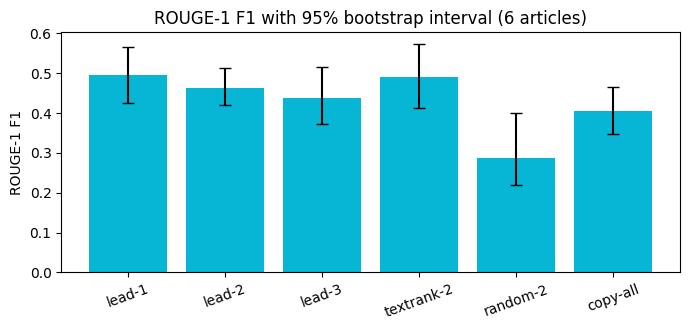

In [9]:
def bootstrap_ci(values, B=2000, seed=0, alpha=0.05):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = [values[rng.integers(0, len(values), len(values))].mean() for _ in range(B)]
    return values.mean(), np.quantile(means, alpha / 2), np.quantile(means, 1 - alpha / 2)

rows = []
for name, d in per_article.items():
    m, lo, hi = bootstrap_ci(d["R1_F"])
    rows.append([name, m, lo, hi])
ci = pd.DataFrame(rows, columns=["system", "ROUGE-1 F1", "CI low", "CI high"]).set_index("system")
display(ci)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(ci.index, ci["ROUGE-1 F1"], yerr=[ci["ROUGE-1 F1"] - ci["CI low"], ci["CI high"] - ci["ROUGE-1 F1"]],
       capsize=4, color="#06b6d4")
ax.set_ylabel("ROUGE-1 F1"); ax.set_title("ROUGE-1 F1 with 95% bootstrap interval (6 articles)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

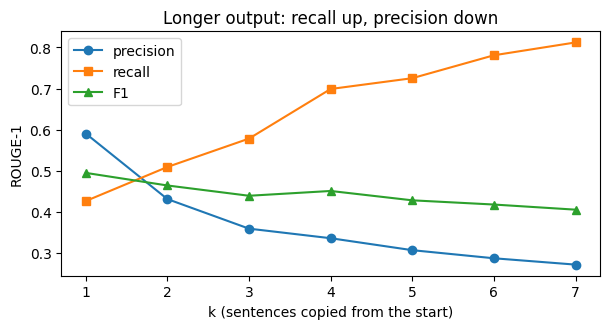

In [10]:
# Precision / recall trade-off as the summary gets longer (Lead-k, k = 1..7)
ks = range(1, 8)
P_, R_, F_ = [], [], []
for k in ks:
    d = score_system([lead_k(a["text"], k) for a in ARTICLES], REFS)
    P_.append(np.mean(d["R1_P"])); R_.append(np.mean(d["R1_R"])); F_.append(np.mean(d["R1_F"]))
plt.figure(figsize=(6.2, 3.4))
plt.plot(list(ks), P_, "o-", label="precision"); plt.plot(list(ks), R_, "s-", label="recall"); plt.plot(list(ks), F_, "^-", label="F1")
plt.xlabel("k (sentences copied from the start)"); plt.ylabel("ROUGE-1"); plt.legend(); plt.title("Longer output: recall up, precision down")
plt.tight_layout(); plt.show()

## Part 4: Abstractive summarization with a real model (Colab)

An **abstractive** summarizer writes new sentences. We use **DistilBART fine-tuned on CNN/DailyMail** (`sshleifer/distilbart-cnn-12-6`). It needs internet (to download about 1.2 GB) and runs on CPU or GPU.

If the model cannot be loaded, the cell prints a message and uses the TextRank summaries as a **stand-in**, so every later cell still runs. The label `ABSTRACTIVE_NAME` tells you which one you have.

In [11]:
ABSTRACTIVE = None
ABSTRACTIVE_NAME = None
if USE_MODELS:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        device = "cuda" if torch.cuda.is_available() else "cpu"
        MODEL = "sshleifer/distilbart-cnn-12-6"
        tokz = AutoTokenizer.from_pretrained(MODEL)
        seq2seq = AutoModelForSeq2SeqLM.from_pretrained(MODEL).to(device).eval()

        def abstractive_summary(text, max_len=70, min_len=20):
            enc = tokz(text, return_tensors="pt", truncation=True, max_length=1024).to(device)
            with torch.no_grad():
                out = seq2seq.generate(**enc, num_beams=4, max_length=max_len, min_length=min_len,
                                       no_repeat_ngram_size=3, early_stopping=True)
            return tokz.decode(out[0], skip_special_tokens=True)

        ABSTRACTIVE = [abstractive_summary(a["text"]) for a in ARTICLES]
        ABSTRACTIVE_NAME = "distilbart-cnn"
        print("Real abstractive model loaded:", MODEL, "on", device)
    except Exception as e:
        print(f"Model not available here ({type(e).__name__}). Using TextRank summaries as a stand-in.")
if ABSTRACTIVE is None:
    ABSTRACTIVE = SYSTEMS["textrank-2"]
    ABSTRACTIVE_NAME = "abstractive (stand-in: textrank-2)"

SYSTEMS[ABSTRACTIVE_NAME] = ABSTRACTIVE
print("\nSystem under test:", ABSTRACTIVE_NAME)
print("Summary of article 1:", ABSTRACTIVE[0])

config.json:   0%|          | 0.00/1.80k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

Real abstractive model loaded: sshleifer/distilbart-cnn-12-6 on cpu

System under test: distilbart-cnn
Summary of article 1:  The city council of Marlow voted 7 to 2 on Tuesday to build 40 kilometres of protected bike lanes . The plan will cost 18 million euros and is partly funded by a national transport grant . Cycling already accounts for 9 percent of trips in Marlow, up from 4 percent in 2018 .


In [12]:
per_article[ABSTRACTIVE_NAME] = score_system(ABSTRACTIVE, REFS)
table = pd.DataFrame({name: {k: np.mean(v) for k, v in d.items()} for name, d in per_article.items()}).T
display(table.loc[[ABSTRACTIVE_NAME, "lead-2", "textrank-2", "random-2"]])

,R1_P,R1_R,R1_F,R2_F,RL_F
distilbart-cnn,0.394,0.474,0.421,0.207,0.306
lead-2,0.431,0.509,0.464,0.245,0.370
textrank-2,0.478,0.508,0.490,0.262,0.389
random-2,0.299,0.275,0.286,0.110,0.229


## Part 5: BERTScore, matching words by meaning

ROUGE needs the *same word*. **BERTScore** (Zhang et al., ICLR 2020) embeds every token and matches each candidate token to its **most similar** reference token (cosine similarity):

* **Precision** = mean over candidate tokens of the best similarity in the reference
* **Recall** = mean over reference tokens of the best similarity in the candidate
* **F1** = harmonic mean

First the exact example from slide 4, then two embeddings: a tiny offline one, and the real BERT model.

In [13]:
def bertscore_from_sim(S):
    # S[i, j] = cosine similarity between candidate token i and reference token j
    S = np.asarray(S, dtype=float)
    P = S.max(axis=1).mean()      # for each candidate token, its best reference match
    R = S.max(axis=0).mean()      # for each reference token, its best candidate match
    F = 2 * P * R / (P + R) if (P + R) else 0.0
    return P, R, F

# Illustrative similarities from slide 4 (rows: feline, rested, rug, on; columns: cat, sat, mat)
S_toy = [[0.9, 0.2, 0.1], [0.3, 0.8, 0.2], [0.1, 0.3, 0.7], [0.2, 0.1, 0.4]]
P, R, F = bertscore_from_sim(S_toy)
print(f"P = {P:.2f}   R = {R:.2f}   F1 = {F:.3f}")
assert abs(P - 0.70) < 1e-9 and abs(R - 0.80) < 1e-9 and abs(F - 0.7467) < 1e-3
print("Matches slide 4: P = 0.70, R = 0.80, F1 = 0.75")

P = 0.70   R = 0.80   F1 = 0.747
Matches slide 4: P = 0.70, R = 0.80, F1 = 0.75


In [14]:
# A tiny OFFLINE embedding: hash character trigrams into a 512-dimensional vector (like fastText subwords).
# Words that share letters ("walked", "walking") get similar vectors. It cannot know that "cat" ~ "feline":
# that needs a trained model such as BERT (next cell). This is why we call it BERTScore-lite.
DIM = 512
def word_vec(w):
    w = f"<{w}>"
    v = np.zeros(DIM)
    for i in range(len(w) - 2):
        h = zlib.crc32(w[i:i + 3].encode())
        v[h % DIM] += 1.0 if (h >> 9) & 1 else -1.0
    n = np.linalg.norm(v)
    return v / n if n else v

def bertscore_lite(ref, cand):
    r, c = tok(ref), tok(cand)
    if not r or not c:
        return 0.0, 0.0, 0.0
    S = np.array([[word_vec(ci) @ word_vec(rj) for rj in r] for ci in c])
    return bertscore_from_sim(S)

for name, cand in toy.items():
    print(f"{name:22s} BERTScore-lite F1 = {bertscore_lite(ref, cand)[2]:.3f}   ROUGE-1 F1 = {rouge_n(ref, cand, 1)[2]:.3f}")
print("\nNote: the lite version still cannot see that 'feline' means 'cat'. A real model can.")

small edit (lay)       BERTScore-lite F1 = 0.860   ROUGE-1 F1 = 0.833
WRONG fact (dog)       BERTScore-lite F1 = 0.860   ROUGE-1 F1 = 0.833
paraphrase (feline)    BERTScore-lite F1 = 0.400   ROUGE-1 F1 = 0.333

Note: the lite version still cannot see that 'feline' means 'cat'. A real model can.


In [15]:
# The REAL BERTScore (pip package bert-score) with a small BERT model. Needs internet on Colab.
def bertscore_real(cands, refs, model_type="distilbert-base-uncased"):
    try:
        from bert_score import score
        P, R, F = score(cands, refs, model_type=model_type, lang="en", verbose=False)
        return P.numpy(), R.numpy(), F.numpy()
    except Exception as e:
        print(f"Real BERTScore not available here ({type(e).__name__}); using BERTScore-lite.")
        return None

res = bertscore_real(list(toy.values()), [ref] * 3) if USE_MODELS else None
if res is not None:
    print(pd.DataFrame({"candidate": list(toy), "BERTScore F1 (real)": res[2],
                        "ROUGE-1 F1": [rouge_n(ref, c, 1)[2] for c in toy.values()]}))
    print("\nThe paraphrase now scores well above its ROUGE value: contextual embeddings know feline ~ cat.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


             candidate  BERTScore F1 (real)  ROUGE-1 F1
0     small edit (lay)                0.974       0.833
1     WRONG fact (dog)                0.978       0.833
2  paraphrase (feline)                0.873       0.333

The paraphrase now scores well above its ROUGE value: contextual embeddings know feline ~ cat.


In [16]:
# Score every system with BERTScore (real if available, otherwise lite)
BERT_NAME = "BERTScore-lite"
bert_f = {}
first = bertscore_real(list(SYSTEMS.values())[0], REFS) if USE_MODELS else None   # probe once
if first is not None:                                  # real model available: use it for EVERY system
    BERT_NAME = "BERTScore (distilbert)"
    for name, cands in SYSTEMS.items():
        bert_f[name] = [float(x) for x in bertscore_real(cands, REFS)[2]]
else:                                                  # offline: use the lite version for every system
    for name, cands in SYSTEMS.items():
        bert_f[name] = [bertscore_lite(r, c)[2] for r, c in zip(REFS, cands)]
print("BERTScore variant used for the table:", BERT_NAME)
compare = pd.DataFrame({"ROUGE-1 F1": {n: np.mean(per_article[n]["R1_F"]) for n in SYSTEMS},
                        "ROUGE-L F1": {n: np.mean(per_article[n]["RL_F"]) for n in SYSTEMS},
                        BERT_NAME: {n: np.mean(v) for n, v in bert_f.items()}})
display(compare.sort_values("ROUGE-1 F1", ascending=False))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (8 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERTScore variant used for the table: BERTScore (distilbert)


,ROUGE-1 F1,ROUGE-L F1,BERTScore (distilbert)
lead-1,0.495,0.385,0.859
textrank-2,0.490,0.389,0.862
lead-2,0.464,0.370,0.853
lead-3,0.439,0.345,0.850
distilbart-cnn,0.421,0.306,0.842
copy-all,0.405,0.328,0.856
random-2,0.286,0.229,0.803


## Part 6: Factual consistency, does the summary tell the truth?

Overlap metrics cannot detect a false statement. Two ways to check **consistency** with the source:

**(a) Entity and number support (our own simple metric).** Collect the *anchors* of a summary (numbers and capitalised names that are not the first word of a sentence). The **support rate** is the share of anchors that also appear in the article. A swapped number or name lowers it.

**(b) NLI-based, SummaC-style.** A Natural Language Inference model says whether a source sentence *entails* a summary sentence. For each summary sentence take the **maximum** entailment over source sentences, then average. The notebook uses `facebook/bart-large-mnli` on Colab and a lexical-containment stand-in offline.

In [17]:
def norm_anchor(w):
    w = w.lower().replace("’s", "").replace("'s", "").replace(",", "")
    if len(w) > 3 and w.endswith("s"):
        w = w[:-1]
    return w

def clean_word(w):
    return w.strip('.,;:!?"()')

NUM = re.compile(r"\d[\d,]*(\.\d+)?")

def anchors(text):
    out = []
    for sent in sentences(text):
        for i, w in enumerate(sent.split()):
            c = clean_word(w)
            if not c:
                continue
            if NUM.fullmatch(c) or (i > 0 and c[0].isupper()):
                out.append(norm_anchor(c))
    return out

def support_rate(summary, article):
    vocab = {norm_anchor(clean_word(w)) for w in article.split()}
    a = anchors(summary)
    return 1.0 if not a else sum(x in vocab for x in a) / len(a)

# human references must be fully supported by their articles
for art in ARTICLES:
    s = support_rate(art["reference"], art["text"])
    assert s == 1.0, (art["id"], s, anchors(art["reference"]))
print("All human references have support rate 1.0")
print("Anchors in reference 1:", anchors(ARTICLES[0]["reference"]))

All human references have support rate 1.0
Anchors in reference 1: ['40', '2028', '18', 'harbour', 'street', '120']


In [18]:
STOP = set("a an the of to in on at by for and or but is are was were be been it its this that these those with as from".split())

def lexical_entail(premise, hypothesis):
    # Offline stand-in for an NLI model: share of the hypothesis content words found in the premise.
    h = [w for w in tok(hypothesis) if w not in STOP]
    p = set(tok(premise))
    return sum(w in p for w in h) / len(h) if h else 1.0

def summac_zs(article, summary, entail_fn):
    # For each summary sentence: best entailment over source sentences; then average over summary sentences.
    src = sentences(article)
    scores = [max(entail_fn(s, hyp) for s in src) for hyp in sentences(summary)]
    return float(np.mean(scores)) if scores else 0.0

NLI_NAME = "lexical stand-in"
entail_fn = lexical_entail
if USE_MODELS:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        nli_tok = AutoTokenizer.from_pretrained("facebook/bart-large-mnli")
        nli_model = AutoModelForSequenceClassification.from_pretrained("facebook/bart-large-mnli").to(dev).eval()
        ent_idx = [i for i, l in nli_model.config.id2label.items() if l.lower() == "entailment"][0]
        def nli_entail(premise, hypothesis):
            enc = nli_tok(premise, hypothesis, return_tensors="pt", truncation=True, max_length=512).to(dev)
            with torch.no_grad():
                probs = torch.softmax(nli_model(**enc).logits, dim=-1)[0]
            return float(probs[ent_idx])
        nli_entail("The cat sat on the mat.", "A cat is on a mat.")      # smoke test
        entail_fn, NLI_NAME = nli_entail, "bart-large-mnli"
        print("Real NLI model loaded.")
    except Exception as e:
        print(f"NLI model not available here ({type(e).__name__}); using the lexical stand-in.")
print("Entailment scorer in use:", NLI_NAME)

arts = [a["text"] for a in ARTICLES]
rows = {}
for name, cands in SYSTEMS.items():
    rows[name] = {"support rate": np.mean([support_rate(c, a) for c, a in zip(cands, arts)]),
                  "SummaC-ZS (" + NLI_NAME + ")": np.mean([summac_zs(a, c, entail_fn) for c, a in zip(cands, arts)]),
                  "ROUGE-1 F1": np.mean(per_article[name]["R1_F"])}
rows["human reference"] = {"support rate": np.mean([support_rate(a["reference"], a["text"]) for a in ARTICLES]),
                           "SummaC-ZS (" + NLI_NAME + ")": np.mean([summac_zs(a["text"], a["reference"], entail_fn) for a in ARTICLES]),
                           "ROUGE-1 F1": 1.0}
display(pd.DataFrame(rows).T)
print("Extractive summaries copy source sentences, so they are consistent by construction.")
print("Note: the offline lexical stand-in scores the human (abstractive) reference LOWER than copied text, because")
print("rewording lowers word containment. A real NLI model understands rewording; that is why NLI metrics exist.")
print("The interesting test is next: inject errors and see which metric notices.")

config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Real NLI model loaded.
Entailment scorer in use: bart-large-mnli


,support rate,SummaC-ZS (bart-large-mnli),ROUGE-1 F1
lead-1,1.0,0.903,0.495
lead-2,1.0,0.900,0.464
lead-3,1.0,0.923,0.439
textrank-2,1.0,0.911,0.490
random-2,1.0,0.942,0.286
copy-all,1.0,0.952,0.405
distilbart-cnn,1.0,0.818,0.421
human reference,1.0,0.167,1.000


Extractive summaries copy source sentences, so they are consistent by construction.
Note: the offline lexical stand-in scores the human (abstractive) reference LOWER than copied text, because
rewording lowers word containment. A real NLI model understands rewording; that is why NLI metrics exist.
The interesting test is next: inject errors and see which metric notices.


### Hallucination injection: ROUGE barely moves, support collapses

We take each summary and **swap every number** for a wrong one (a typical hallucination). Same length, same style, wrong facts. A good consistency metric should drop sharply; ROUGE should not.

In [19]:
def swap_numbers(text):
    def f(m):
        n = float(m.group(0).replace(",", ""))
        return str(int(n * 3 + 7))
    return NUM.sub(f, text)

rows = []
for name in ["human reference", "lead-2", "textrank-2", ABSTRACTIVE_NAME]:
    cands = REFS if name == "human reference" else SYSTEMS[name]
    bad = [swap_numbers(c) for c in cands]
    rows.append([name,
                 np.mean([rouge_n(r, c, 1)[2] for r, c in zip(REFS, cands)]), np.mean([rouge_n(r, b, 1)[2] for r, b in zip(REFS, bad)]),
                 np.mean([support_rate(c, a) for c, a in zip(cands, arts)]), np.mean([support_rate(b, a) for b, a in zip(bad, arts)])])
inj = pd.DataFrame(rows, columns=["summary", "ROUGE-1 before", "ROUGE-1 after", "support before", "support after"]).set_index("summary")
display(inj)
print("Example (article 1):")
print("  original :", ARTICLES[0]["reference"])
print("  corrupted:", swap_numbers(ARTICLES[0]["reference"]))

,ROUGE-1 before,ROUGE-1 after,support before,support after
summary,,,,
human reference,1.000,0.892,1.0,0.222
lead-2,0.464,0.393,1.0,0.469
textrank-2,0.490,0.399,1.0,0.350
distilbart-cnn,0.421,0.367,1.0,0.403


Example (article 1):
  original : Marlow's council approved 40 km of protected bike lanes by 2028, costing 18 million euros. Parking lost on Harbour Street will be replaced with 120 spaces nearby.
  corrupted: Marlow's council approved 127 km of protected bike lanes by 6091 costing 61 million euros. Parking lost on Harbour Street will be replaced with 367 spaces nearby.


## Part 7: Metric sanity test, perturb a good summary

A powerful way to understand a metric is to **damage a good summary in a known way** and see what the metric notices. We start from the human reference and apply:

| Perturbation | What is damaged |
|---|---|
| `identity` | nothing (upper bound) |
| `paraphrase` | wording only (meaning kept) |
| `drop_sentence` | information is lost |
| `add_irrelevant` | an off-topic sentence is added |
| `shuffle_words` | grammar and order destroyed (same bag of words) |
| `swap_facts` | numbers are wrong (fluent but false) |

Compare how ROUGE-1, ROUGE-L, BERTScore-lite and the support rate react.

In [20]:
PARA = {"approved": "passed", "found": "discovered", "rose": "increased", "plans": "intends", "costing": "priced at",
        "survey": "census", "helped": "assisted", "concern": "worry", "strong": "powerful", "threat": "danger",
        "replaced": "substituted", "reviewed": "assessed", "retain": "keep", "counted": "tallied", "astronomers": "scientists",
        "little": "minimal", "benefit": "gain", "critics": "sceptics", "walk": "stroll", "linked": "associated", "risk": "danger",
        "profit": "earnings", "hire": "recruit", "expect": "anticipate", "delays": "setbacks", "move": "switch", "begin": "start"}

def paraphrase(text):
    return re.sub(r"[A-Za-z]+", lambda m: PARA.get(m.group(0).lower(), m.group(0)) if m.group(0).lower() in PARA else m.group(0), text)

def drop_sentence(text):
    return sentences(text)[0]

def add_irrelevant(text):
    return text + " The weather this week has been mild."

def shuffle_words(text, seed=0):
    w = text.split(); random.Random(seed).shuffle(w); return " ".join(w)

PERTURB = {"identity": lambda t: t, "paraphrase": paraphrase, "drop_sentence": drop_sentence,
           "add_irrelevant": add_irrelevant, "shuffle_words": shuffle_words, "swap_facts": swap_numbers}

records = []
for pname, fn in PERTURB.items():
    for art in ARTICLES:
        cand = fn(art["reference"])
        records.append(dict(perturbation=pname, article=art["id"], candidate=cand,
                            R1=rouge_n(art["reference"], cand, 1)[2], R2=rouge_n(art["reference"], cand, 2)[2],
                            RL=rouge_l(art["reference"], cand)[2], BERT_lite=bertscore_lite(art["reference"], cand)[2],
                            support=support_rate(cand, art["text"])))
rec = pd.DataFrame(records)
sanity = rec.groupby("perturbation")[["R1", "R2", "RL", "BERT_lite", "support"]].mean().loc[list(PERTURB)]
display(sanity)
print("Example paraphrase:", rec[(rec.perturbation == "paraphrase") & (rec.article == "bike")].candidate.iloc[0])
print("Example shuffle   :", rec[(rec.perturbation == "shuffle_words") & (rec.article == "bike")].candidate.iloc[0])

,R1,R2,RL,BERT_lite,support
perturbation,,,,,
identity,1.000,1.000,1.000,1.000,1.000
paraphrase,0.843,0.720,0.843,0.870,1.000
drop_sentence,0.787,0.778,0.787,0.852,1.000
add_irrelevant,0.898,0.895,0.898,0.922,1.000
shuffle_words,1.000,0.101,0.312,1.000,1.000
swap_facts,0.892,0.792,0.892,0.903,0.222


Example paraphrase: Marlow's council passed 40 km of protected bike lanes by 2028, priced at 18 million euros. Parking lost on Harbour Street will be substituted with 120 spaces nearby.
Example shuffle   : 40 euros. 2028, on of Marlow's bike be Street Harbour with spaces km approved replaced protected costing will by nearby. Parking lost lanes council million 120 18


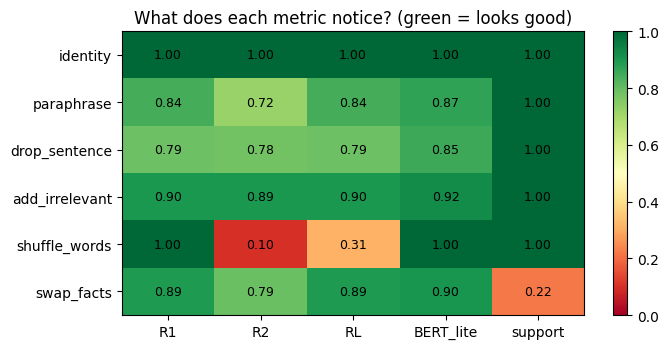

In [21]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
im = ax.imshow(sanity.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(sanity.shape[1])); ax.set_xticklabels(sanity.columns)
ax.set_yticks(range(sanity.shape[0])); ax.set_yticklabels(sanity.index)
for i in range(sanity.shape[0]):
    for j in range(sanity.shape[1]):
        ax.text(j, i, f"{sanity.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("What does each metric notice? (green = looks good)")
plt.colorbar(im); plt.tight_layout(); plt.show()

**How to read the heat-map**

* `shuffle_words`: ROUGE-1 and the support rate stay at 1.0 (same words!), only ROUGE-2 and ROUGE-L collapse. A bag-of-words metric cannot see broken grammar.
* `swap_facts`: ROUGE barely drops (only the numbers changed) but the **support rate falls**. Overlap metrics are blind to fluent falsehoods.
* `paraphrase`: all overlap metrics punish a harmless rewording.
* `add_irrelevant` and `drop_sentence`: no consistency problem, but the information content changes. Support does not notice; ROUGE-recall does for dropped content.

**No single metric catches everything**, which is the main message of the presentation.

## Part 8: Meta-evaluation, do metrics agree with a quality ordering?

To judge a *metric* we compare its scores with human quality ratings (usually Spearman or Kendall correlation). Real studies use thousands of human ratings (for example SummEval). Here we use an **assumed ordering written by us** for the six perturbations, only to practise the method:

`identity (6) > paraphrase (5) > add_irrelevant (4) > drop_sentence (3) > shuffle_words (2) > swap_facts (1)`

Replace it with real annotations when you have them.

In [22]:
ASSUMED = {"identity": 6, "paraphrase": 5, "add_irrelevant": 4, "drop_sentence": 3, "shuffle_words": 2, "swap_facts": 1}
rec["assumed_quality"] = rec["perturbation"].map(ASSUMED)
rows = {}
for m in ["R1", "R2", "RL", "BERT_lite", "support"]:
    rows[m] = {"Spearman": spearmanr(rec[m], rec["assumed_quality"])[0], "Kendall tau": kendalltau(rec[m], rec["assumed_quality"])[0]}
# a simple combination: average of a fluency-sensitive metric and a consistency metric
rec["R2+support"] = (rec["R2"] + rec["support"]) / 2
rows["R2+support"] = {"Spearman": spearmanr(rec["R2+support"], rec["assumed_quality"])[0],
                      "Kendall tau": kendalltau(rec["R2+support"], rec["assumed_quality"])[0]}
meta = pd.DataFrame(rows).T
display(meta)
print("Combining a fluency-sensitive metric with a consistency metric correlates better than either alone.")
print("Lesson: report several metrics and validate them against humans (Spearman, Kendall, Cohen's kappa).")

,Spearman,Kendall tau
R1,0.096,0.073
R2,0.570,0.424
RL,0.490,0.383
BERT_lite,0.114,0.071
support,0.651,0.558
R2+support,0.848,0.696


Combining a fluency-sensitive metric with a consistency metric correlates better than either alone.
Lesson: report several metrics and validate them against humans (Spearman, Kendall, Cohen's kappa).


## Summary

| Metric | What it measures | Blind spot (seen in this notebook) |
|---|---|---|
| ROUGE-1/2/L | word, word-pair, ordered overlap | paraphrase punished; false facts not noticed; recall gamed by length |
| BERTScore | token matching by embedding similarity | the offline lite version only sees spelling; real BERT sees meaning but not truth |
| Support rate | numbers and names found in the source | ignores irrelevant content and grammar |
| SummaC-style NLI | does the source entail each summary sentence | needs a good NLI model; sentence level |

**Exercises**

1. Add a sixth article from CNN/DailyMail (the optional cell) and rerun the comparison table.
2. Implement **ROUGE-Lsum** (summary-level LCS) and compare with ROUGE-L on the two-sentence summaries.
3. Implement a metric for **compression ratio** (summary length / article length) and plot it against ROUGE-1 F1.
4. Replace `swap_numbers` with a function that swaps **names**, and check which metric reacts.
5. On Colab, change the model to `facebook/bart-large-cnn` and compare ROUGE with DistilBART.

**References:** Lin (2004) ROUGE; Zhang et al. (2020) BERTScore; Fabbri et al. (2021) SummEval; Laban et al. (2022) SummaC; Zha et al. (2023) AlignScore; Ramprasad and Wallace (2024) on gaming factuality metrics.